In [ ]:
import os
import cv2
import time
import random
import numpy as np
import zipfile

import tensorflow as tf
from tensorflow.keras import backend, layers, metrics

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import Xception
from tensorflow.keras.models import Model, Sequential

from tensorflow.keras.utils import plot_model
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
random.seed(3)
np.random.seed(3)
tf.random.set_seed(3)

ROOT = "/content/drive/MyDrive/Siamese Face Recognition"
KAGGLE_ROOT = os.path.join(ROOT, 'data/kaggle/Extracted Faces')
CUSTOM_ROOT = os.path.join(ROOT,'data/custom/Extracted')  # one folder per person, cropped faces
MODEL_ROOT = os.path.join(ROOT, 'model-siamese')

load_model = True
save_all = False
path = "training"
checkpoint_path = os.path.join(MODEL_ROOT, path)
checkpoint_dir = os.path.dirname(checkpoint_path)
epochs = 15

# Data ETL

In [ ]:
# with zipfile.ZipFile(ROOT+'/kaggle/Kaggle_Dataset_Face_Recognition.zip', 'r') as zip_ref:
#     zip_ref.extractall(ROOT+'/kaggle')

## Prepare your own dataset

No dataset is included in this repository. Collect your own face photos, with the consent of the people in them: several people, multiple photos per person (at least 2, 10 or more is better), varied lighting and angles, one clear face per photo.

Organise them as one folder per person (named with an ID), then crop the faces with the helper below. It crops in place and deletes the original files, so run it on a copy. The cropped folders go under the dataset root set as `CUSTOM_ROOT` further down.

In [ ]:
import os
import cv2

def detect_and_crop_faces(image_path, dirname, filename):    
    # Load the Haar cascade face detection model
    face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

    # Read the image
    image = cv2.imread(image_path)

    # Convert the image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Detect faces in the image
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))

    x, y, w, h = faces[0]
    # Calculate the coordinates of the bounding box
    x1 = x
    y1 = y
    x2 = x + w
    y2 = y + h

    # Crop the image around the face, maintaining color channels
    cropped_face = image[y1:y2, x1:x2].copy()

    # Save the cropped face as a new image
    file_jpg = f"{filename}.jpg"
    save_path = os.path.join(dirname, file_jpg)
    cv2.imwrite(save_path, cropped_face)
#     print(f"Saved {save_path}.")


def get_folder_paths(folder_path):
    folder_paths = []
    for root, dirs, files in os.walk(folder_path):
        for dir_ in dirs:
            path = os.path.join(root, dir_)
            folder_paths.append(path)
    return folder_paths

def get_file_paths(folder_path):
    file_paths = []
    for root, dirs, files in os.walk(folder_path):
        for file in files:
            file_path = os.path.join(root, file)
            file_paths.append(file_path)
    return file_paths

def remove_file(path):
    os.remove(path)
#     print(f"{path} Deleted")

def detect_faces(folder_list):
    
    for folder in folder_list:
        print(f"Processing {folder[-20:]}")
        
        try:
            files = get_file_paths(folder)
        except Exception as e:
            print(f"Get File Path for {folder} Error with value: {e}")
            continue
        
#         print(files)
        for i, filepath in enumerate(files):
            try:
                detect_and_crop_faces(filepath, folder, str(i+1))
                remove_file(filepath)
            except Exception as e:
                print(f"Detect and crop face for {filepath} Error with value: {e}")
        
        print("Done")

# Example (crops faces in place and deletes the original files, so work on a copy):
# detect_faces(get_folder_paths("path/to/unprocessed_photos"))


In [ ]:
def get_num_files(directory, folders):
  ret_map = {}

  for folder in folders:
    num_files = len(os.listdir(os.path.join(directory, folder)))
    ret_map[folder] = num_files

  return ret_map

def split_dataset(directory, train_size=0.9):
  folders = os.listdir(directory)
  random.shuffle(folders)

  cut = int(len(folders) * train_size)

  train_map = get_num_files(directory, folders[:cut])
  test_map = get_num_files(directory, folders[cut:])

  return train_map, test_map

In [ ]:
def create_triplets(directory, folder_list, max_files=10):
    triplets = []
    folders = list(folder_list.keys())

    for folder in folders:
        path = os.path.join(directory, folder)
        files = list(os.listdir(path))[:max_files]
        num_files = len(files)

        for i in range(num_files-1):
            for j in range(i+1, num_files):
                anchor = (directory, folder, files[i])
                positive = (directory, folder, files[j])

                neg_folder = random.choice(folders)
                while neg_folder == folder:
                   neg_folder = random.choice(folders)

                neg_file = random.choice(os.listdir(os.path.join(directory, neg_folder)))
                negative = (directory, neg_folder, neg_file)

                triplets.append((anchor, positive, negative))

    random.shuffle(triplets)
    return triplets

In [ ]:
def read_image(idx):
    path = os.path.join(idx[0], idx[1], idx[2])
    image = cv2.imread(path)
    image = cv2.resize(image, (224, 224))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    return image

def get_batch(triplet_list, batch_size=256):
    batch_steps = len(triplet_list)//batch_size

    for i in range(batch_steps+1):
        anchor   = []
        positive = []
        negative = []

        j = i*batch_size
        while j<(i+1)*batch_size and j<len(triplet_list):
            a, p, n = triplet_list[j]
            anchor.append(read_image(a))
            positive.append(read_image(p))
            negative.append(read_image(n))
            j+=1

        anchor = np.array(anchor)
        positive = np.array(positive)
        negative = np.array(negative)

        yield ([anchor, positive, negative])

### From Your Own Dataset

In [ ]:
train_list_custom, test_list_custom = split_dataset(CUSTOM_ROOT, train_size=0.5)
print("Length of training list:", len(train_list_custom))
print("Length of testing list :", len(test_list_custom))

# train_list, test list contains the folder names along with the number of files in the folder.
print("\nTest List:", test_list_custom)

In [ ]:
train_triplet_custom = create_triplets(CUSTOM_ROOT, train_list_custom)
test_triplet_custom  = create_triplets(CUSTOM_ROOT, test_list_custom)

print("Number of training triplets:", len(train_triplet_custom))
print("Number of testing triplets :", len(test_triplet_custom))

print("\nExamples of triplets:")
for i in range(5):
    print(train_triplet_custom[i])

In [ ]:
num_plots = 6

f, axes = plt.subplots(num_plots, 3, figsize=(15, 20))

for x in get_batch(train_triplet_custom, batch_size=num_plots):
    a,p,n = x
    for i in range(num_plots):
        axes[i, 0].imshow(a[i])
        axes[i, 1].imshow(p[i])
        axes[i, 2].imshow(n[i])
        i+=1
    break

In [ ]:
# Joining train list
train_triplet = train_triplet_custom
test_triplet = test_triplet_custom

print("Number of training triplets:", len(train_triplet))
print("Number of testing triplets :", len(test_triplet))

print("\nExamples of triplets:")
for i in range(5):
    print(train_triplet[i])

# Evaluate Model

In [ ]:
encoder = tf.keras.models.load_model('/content/drive/MyDrive/Siamese Face Recognition/encoder-model-v2')
encoder.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 zero_padding2d_13 (ZeroPadd  (None, 226, 226, 3)      0         
 ing2D)                                                          
                                                                 
 conv2d_16 (Conv2D)          (None, 224, 224, 64)      1792      
                                                                 
 zero_padding2d_14 (ZeroPadd  (None, 226, 226, 64)     0         
 ing2D)                                                          
                                                                 
 conv2d_17 (Conv2D)          (None, 224, 224, 64)      36928     
                                                                 
 max_pooling2d_5 (MaxPooling  (None, 112, 112, 64)     0         
 2D)                                                             
                                                      

In [ ]:
def classify_images(face_list1, face_list2, threshold=1.3):
    # Getting the encodings for the passed faces
    tensor1 = encoder.predict(face_list1)
    tensor2 = encoder.predict(face_list2)

    distance = np.sum(np.square(tensor1-tensor2), axis=-1)
    prediction = np.where(distance<threshold, 0, 1)
    return prediction

8/8 [==============================] - 1s 179ms/step

Accuracy of model: 0.826171875



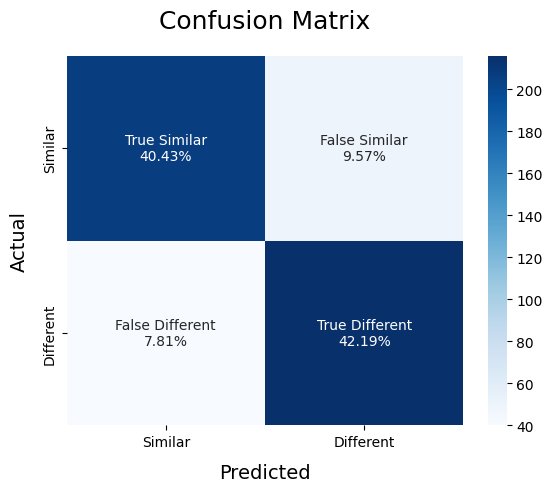

In [ ]:
def ModelMetrics(pos_list, neg_list):
    true = np.array([0]*len(pos_list)+[1]*len(neg_list))
    pred = np.append(pos_list, neg_list)

    # Compute and print the accuracy
    print(f"\nAccuracy of model: {accuracy_score(true, pred)}\n")

    # Compute and plot the Confusion matrix
    cf_matrix = confusion_matrix(true, pred)

    categories  = ['Similar','Different']
    names = ['True Similar','False Similar', 'False Different','True Different']
    percentages = ['{0:.2%}'.format(value) for value in cf_matrix.flatten() / np.sum(cf_matrix)]

    labels = [f'{v1}\n{v2}' for v1, v2 in zip(names, percentages)]
    labels = np.asarray(labels).reshape(2,2)

    sns.heatmap(cf_matrix, annot = labels, cmap = 'Blues',fmt = '',
                xticklabels = categories, yticklabels = categories)

    plt.xlabel("Predicted", fontdict = {'size':14}, labelpad = 10)
    plt.ylabel("Actual"   , fontdict = {'size':14}, labelpad = 10)
    plt.title ("Confusion Matrix", fontdict = {'size':18}, pad = 20)


pos_list = np.array([])
neg_list = np.array([])

for data in get_batch(test_triplet, batch_size=256):
    a, p, n = data
    pos_list = np.append(pos_list, classify_images(a, p))
    neg_list = np.append(neg_list, classify_images(a, n))
    break

ModelMetrics(pos_list, neg_list)